## Created - Classifier Baseline

In [27]:
import pandas as pd

from data_access.config import project_path


dataset = pd.read_csv(
    project_path.artifact("task_snapshots_v1.csv.gz")
)

created_df = dataset[
    dataset["Snapshot_Type"] == "created"
].copy()

created_df.head(10)

,Issue_ID,Creation_Date,Resolution_Date,Snapshot_Type,Snapshot_Date,Project_ID,Priority_At_Snapshot,Type_At_Snapshot,Status_At_Snapshot,Age_Hours,...,Sprint_Change_Count,Hours_Since_Last_Change,Hours_Since_Last_Status_Change,Hours_Since_Last_Comment,Remaining_Duration_Hours,Raw_Priority_At_Snapshot,Raw_Type_At_Snapshot,Raw_Status_At_Snapshot,Duration_Class,Split
0,85,2016-02-24 10:51:02,2016-12-23 14:49:45,created,2016-02-24 10:51:02,1,P4,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,7275.9786,Minor,Bug,To Do,30-365d,train
1,86,2016-02-23 18:31:38,2016-12-23 14:49:26,created,2016-02-23 18:31:38,1,P4,Improvement,to do,0.0,...,0.0,NaN,NaN,NaN,7292.2967,Minor,Improvement,To Do,30-365d,train
2,89,2016-02-22 15:27:31,2016-02-22 18:41:31,created,2016-02-22 15:27:31,1,P4,Story,to do,0.0,...,0.0,NaN,NaN,NaN,3.2333,Minor,Story,To Do,0-1d,train
3,90,2016-02-17 14:28:31,2016-02-21 02:28:25,created,2016-02-17 14:28:31,1,P4,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,83.9983,Minor,Bug,To Do,1-7d,train
4,91,2016-02-16 14:59:06,2016-02-19 20:04:19,created,2016-02-16 14:59:06,1,P4,Improvement,to do,0.0,...,0.0,0.0,NaN,NaN,77.0869,Minor,Improvement,To Do,1-7d,train
5,92,2016-02-13 19:04:24,2016-02-21 02:28:36,created,2016-02-13 19:04:24,1,P3,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,175.4033,Major,Bug,To Do,7-30d,train
6,93,2016-02-11 17:45:54,2016-02-21 02:28:22,created,2016-02-11 17:45:54,1,P4,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,224.7078,Minor,Bug,To Do,7-30d,train
7,94,2016-02-05 16:01:49,2016-02-12 22:08:54,created,2016-02-05 16:01:49,1,P3,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,174.1181,Major,Bug,To Do,7-30d,train
8,95,2016-02-03 09:40:06,2016-02-16 15:46:51,created,2016-02-03 09:40:06,1,P4,Story,to do,0.0,...,0.0,NaN,NaN,NaN,318.1125,Minor,Story,To Do,7-30d,train
9,96,2016-02-02 17:52:11,2016-02-03 19:55:37,created,2016-02-02 17:52:11,1,P4,Bug,to do,0.0,...,0.0,NaN,NaN,NaN,26.0572,Minor,Bug,To Do,1-7d,train


In [28]:
pd.crosstab(
    created_df["Split"],
    created_df["Duration_Class"],
)

Duration_Class,0-1d,1-7d,30-365d,7-30d
Split,,,,
excluded_train_overlap,6,64,2878,307
excluded_validation_overlap,6,63,3094,252
test,5173,7507,14173,10928
train,33175,37335,60230,42315
validation,6685,7381,10752,9548


In [29]:
train_df = created_df[created_df["Split"] == "train"].copy()
valid_df = created_df[created_df["Split"] == "validation"].copy()
test_df = created_df[created_df["Split"] == "test"].copy()

In [30]:
from data_access.snapshot_dataset import (
    FEATURE_COLUMNS,
    CATEGORICAL_FEATURES,
)


X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df["Duration_Class"].copy()

X_valid = valid_df[FEATURE_COLUMNS].copy()
y_valid = valid_df["Duration_Class"].copy()

X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df["Duration_Class"].copy()


for X in (X_train, X_valid, X_test):
    for column in CATEGORICAL_FEATURES:
        X[column] = X[column].fillna("Unknown").astype(str)

for name, X, y in (
    ("trin", X_train, y_train),
    ("valid", X_valid, y_valid),
    ("test", X_test, y_test),
):
    print(f"{name}: X={X.shape}, y={y.shape}")

trin: X=(173055, 32), y=(173055,)
valid: X=(34366, 32), y=(34366,)
test: X=(37781, 32), y=(37781,)


In [31]:
from catboost import CatBoostClassifier

import joblib


created_classifier = CatBoostClassifier(
    iterations=1000, # max of 1000 steps for a building a tree ensemble
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass", # ?
    cat_features=CATEGORICAL_FEATURES,
    random_seed=42,
    allow_writing_files=False,
)

created_classifier.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid), # validation for quality control
    early_stopping_rounds=100, # stop if the validation quality hasn't improved for 100 iterations
    use_best_model=True,
    verbose=100, # ?
)

joblib.dump(created_classifier, project_path.artifact("created_classifier.joblib"))

0:	learn: 1.3821328	test: 1.3835152	best: 1.3835152 (0)	total: 132ms	remaining: 2m 12s
100:	learn: 1.2940110	test: 1.3651591	best: 1.3536911 (39)	total: 11.5s	remaining: 1m 42s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 1.353691107
bestIteration = 39

Shrink model to first 40 iterations.


['D:\\PROJECTS\\average_task_performance\\artifacts\\created_classifier.joblib']

In [32]:
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

from data_access.snapshot_dataset import CLASS_LABELS


y_valid_pred = created_classifier.predict(X_valid).ravel()

print(
    classification_report(
        y_valid,
        y_valid_pred,
        labels=CLASS_LABELS,
        digits=3,
        zero_division=0,
    )
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_valid, y_valid_pred), 3)
) # average recall per class

              precision    recall  f1-score   support

        0-1d      0.250     0.118     0.160      6685
        1-7d      0.227     0.146     0.177      7381
       7-30d      0.311     0.540     0.395      9548
     30-365d      0.381     0.351     0.365     10752

    accuracy                          0.314     34366
   macro avg      0.292     0.289     0.275     34366
weighted avg      0.303     0.314     0.293     34366

Balanced Accuracy: 0.289


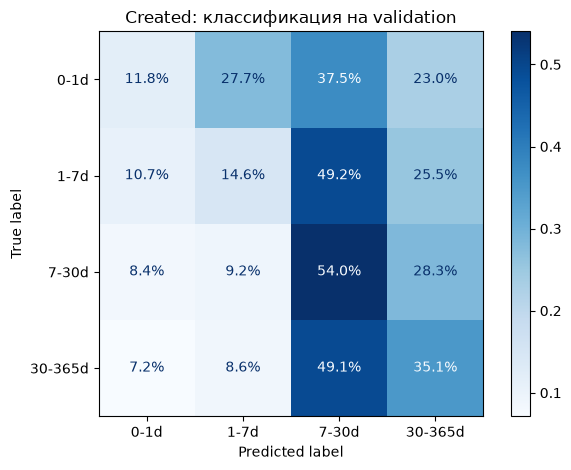

In [33]:
ConfusionMatrixDisplay.from_predictions( # the correct answers are on the diagonal
    y_valid,
    y_valid_pred,
    labels=CLASS_LABELS,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
)

plt.title("Created: классификация на validation") 
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)


majority_class = y_train.mode().iloc[0]
rows = []

for split, X, y in (
    ("train", X_train, y_train),
    ("validation", X_valid, y_valid),
    ("test", X_test, y_test),
):
    predictions = created_classifier.predict(X).ravel()
    baseline_predictions = [majority_class] * len(y)

    for model_name, pred in (
        ("CatBoost", predictions),
        ("Majority baseline", baseline_predictions),
    ):
        rows.append({
            "Split": split,
            "Model": model_name,
            "Accuracy": accuracy_score(y, pred),
            "Balanced accuracy": balanced_accuracy_score(y, pred),
            "Macro F1": f1_score(
                y, pred, average="macro", zero_division=0
            ),
        })

metrics_created_df = pd.DataFrame(rows).set_index(["Split", "Model"])
metrics_created_df.round(3)

Accuracy  Balanced accuracy  Macro F1
Split      Model                                                   
train      CatBoost              0.372              0.288     0.225
           Majority baseline     0.348              0.250     0.129
validation CatBoost              0.314              0.289     0.275
           Majority baseline     0.313              0.250     0.119
test       CatBoost              0.351              0.300     0.294
           Majority baseline     0.375              0.250     0.136

## 24h - Classifier Baseline

In [35]:
import pandas as pd

from data_access.config import project_path


dataset = pd.read_csv(
    project_path.artifact("task_snapshots_v1.csv.gz")
)

h24_df = dataset[
    dataset["Snapshot_Type"] == "24h"
].copy()

h24_df.head(10)

,Issue_ID,Creation_Date,Resolution_Date,Snapshot_Type,Snapshot_Date,Project_ID,Priority_At_Snapshot,Type_At_Snapshot,Status_At_Snapshot,Age_Hours,...,Sprint_Change_Count,Hours_Since_Last_Change,Hours_Since_Last_Status_Change,Hours_Since_Last_Comment,Remaining_Duration_Hours,Raw_Priority_At_Snapshot,Raw_Type_At_Snapshot,Raw_Status_At_Snapshot,Duration_Class,Split
251872,85,2016-02-24 10:51:02,2016-12-23 14:49:45,24h,2016-02-25 10:51:02,1,P4,Bug,to do,24.0,...,0.0,23.9878,NaN,NaN,7251.9786,Minor,Bug,To Do,30-365d,train
251873,86,2016-02-23 18:31:38,2016-12-23 14:49:26,24h,2016-02-24 18:31:38,1,P4,Improvement,to do,24.0,...,0.0,23.9972,NaN,NaN,7268.2967,Minor,Improvement,To Do,30-365d,train
251874,90,2016-02-17 14:28:31,2016-02-21 02:28:25,24h,2016-02-18 14:28:31,1,P4,Bug,to do,24.0,...,1.0,23.9647,NaN,NaN,59.9983,Minor,Bug,To Do,1-7d,train
251875,91,2016-02-16 14:59:06,2016-02-19 20:04:19,24h,2016-02-17 14:59:06,1,P4,Improvement,to do,24.0,...,1.0,9.6011,NaN,NaN,53.0869,Minor,Improvement,To Do,1-7d,train
251876,92,2016-02-13 19:04:24,2016-02-21 02:28:36,24h,2016-02-14 19:04:24,1,P3,Bug,to do,24.0,...,1.0,23.8967,NaN,23.9239,151.4033,Major,Bug,To Do,1-7d,train
251877,93,2016-02-11 17:45:54,2016-02-21 02:28:22,24h,2016-02-12 17:45:54,1,P4,Bug,to do,24.0,...,0.0,NaN,NaN,23.9419,200.7078,Minor,Bug,To Do,7-30d,train
251878,94,2016-02-05 16:01:49,2016-02-12 22:08:54,24h,2016-02-06 16:01:49,1,P3,Bug,in pr,24.0,...,1.0,21.3697,21.3697,NaN,150.1181,Major,Bug,In PR,1-7d,train
251879,95,2016-02-03 09:40:06,2016-02-16 15:46:51,24h,2016-02-04 09:40:06,1,P4,Story,to do,24.0,...,0.0,23.9808,NaN,NaN,294.1125,Minor,Story,To Do,7-30d,train
251880,96,2016-02-02 17:52:11,2016-02-03 19:55:37,24h,2016-02-03 17:52:11,1,P4,Bug,in pr,24.0,...,1.0,21.5856,21.5856,NaN,2.0572,Minor,Bug,In PR,0-1d,train
251881,97,2016-02-01 19:00:42,2016-02-12 22:09:22,24h,2016-02-02 19:00:42,1,P4,Story,in pr,24.0,...,0.0,22.4925,22.4925,NaN,243.1444,Minor,Story,In PR,7-30d,train


In [36]:
pd.crosstab(
    h24_df["Split"],
    h24_df["Duration_Class"]
)

Duration_Class,0-1d,1-7d,30-365d,7-30d
Split,,,,
excluded_train_overlap,5,77,2869,298
excluded_validation_overlap,9,61,3084,255
test,1703,6770,13948,10187
train,9766,31795,59458,38861
validation,1876,6435,10547,8823


In [37]:
train_df = h24_df[h24_df["Split"] == "train"].copy()
valid_df = h24_df[h24_df["Split"] == "validation"].copy()
test_df = h24_df[h24_df["Split"] == "test"].copy()

In [38]:
from data_access.snapshot_dataset import (
    FEATURE_COLUMNS,
    CATEGORICAL_FEATURES,
)


X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df["Duration_Class"].copy()

X_valid = valid_df[FEATURE_COLUMNS].copy()
y_valid = valid_df["Duration_Class"].copy()

X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df["Duration_Class"].copy()


for X in (X_train, X_valid, X_test):
    for column in CATEGORICAL_FEATURES:
        X[column] = X[column].fillna("Unknown").astype(str)

for name, X, y in (
    ("trin", X_train, y_train),
    ("valid", X_valid, y_valid),
    ("test", X_test, y_test),
):
    print(f"{name}: X={X.shape}, y={y.shape}")

trin: X=(139880, 32), y=(139880,)
valid: X=(27681, 32), y=(27681,)
test: X=(32608, 32), y=(32608,)


In [39]:
from catboost import CatBoostClassifier

import joblib


classifier_24h = CatBoostClassifier(
    iterations=1000, # max of 1000 steps for a building a tree ensemble
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass", # ?
    cat_features=CATEGORICAL_FEATURES,
    random_seed=42,
    allow_writing_files=False,
)

classifier_24h.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid), # validation for quality control
    early_stopping_rounds=100, # stop if the validation quality hasn't improved for 100 iterations
    use_best_model=True,
    verbose=100, # ?
)

joblib.dump(classifier_24h, project_path.artifact("classifier_24h.joblib"))

0:	learn: 1.3694473	test: 1.3706739	best: 1.3706739 (0)	total: 112ms	remaining: 1m 51s
100:	learn: 1.1405893	test: 1.1800261	best: 1.1712223 (81)	total: 15.1s	remaining: 2m 14s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 1.171222324
bestIteration = 81

Shrink model to first 82 iterations.


['D:\\PROJECTS\\average_task_performance\\artifacts\\classifier_24h.joblib']

In [40]:
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

from data_access.snapshot_dataset import CLASS_LABELS


y_valid_pred = classifier_24h.predict(X_valid).ravel()

print(
    classification_report(
        y_valid,
        y_valid_pred,
        labels=CLASS_LABELS,
        digits=3,
        zero_division=0,
    )
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_valid, y_valid_pred), 3)
) # average recall per class

              precision    recall  f1-score   support

        0-1d      0.400     0.001     0.002      1876
        1-7d      0.411     0.360     0.384      6435
       7-30d      0.390     0.433     0.411      8823
     30-365d      0.501     0.581     0.539     10547

    accuracy                          0.444     27681
   macro avg      0.426     0.344     0.334     27681
weighted avg      0.438     0.444     0.425     27681

Balanced Accuracy: 0.344


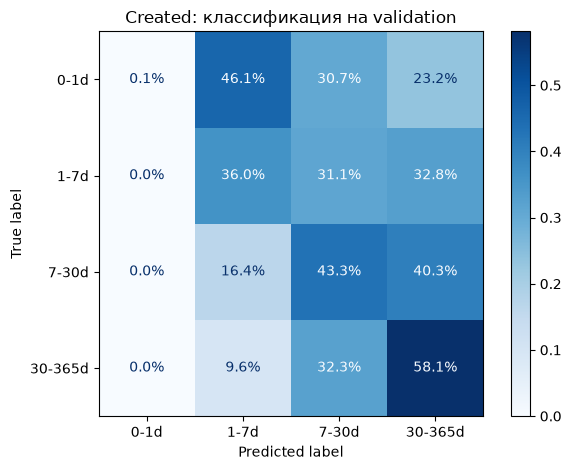

In [41]:
ConfusionMatrixDisplay.from_predictions( # the correct answers are on the diagonal
    y_valid,
    y_valid_pred,
    labels=CLASS_LABELS,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
)

plt.title("Created: классификация на validation") 
plt.tight_layout()
plt.show()

In [42]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)


majority_class = y_train.mode().iloc[0]
rows = []

for split, X, y in (
    ("train", X_train, y_train),
    ("validation", X_valid, y_valid),
    ("test", X_test, y_test),
):
    predictions = classifier_24h.predict(X).ravel()
    baseline_predictions = [majority_class] * len(y)

    for model_name, pred in (
        ("CatBoost", predictions),
        ("Majority baseline", baseline_predictions),
    ):
        rows.append({
            "Split": split,
            "Model": model_name,
            "Accuracy": accuracy_score(y, pred),
            "Balanced accuracy": balanced_accuracy_score(y, pred),
            "Macro F1": f1_score(
                y, pred, average="macro", zero_division=0
            ),
        })

metrics_24h_df = pd.DataFrame(rows).set_index(["Split", "Model"])
metrics_24h_df.round(3)

Accuracy  Balanced accuracy  Macro F1
Split      Model                                                   
train      CatBoost              0.483              0.327     0.301
           Majority baseline     0.425              0.250     0.149
validation CatBoost              0.444              0.344     0.334
           Majority baseline     0.381              0.250     0.138
test       CatBoost              0.440              0.345     0.333
           Majority baseline     0.428              0.250     0.150

## 72h - Classifier Baseline

In [43]:
import pandas as pd

from data_access.config import project_path


dataset = pd.read_csv(
    project_path.artifact("task_snapshots_v1.csv.gz")
)

h72_df = dataset[
    dataset["Snapshot_Type"] == "72h"
].copy()

h72_df.head(10)

,Issue_ID,Creation_Date,Resolution_Date,Snapshot_Type,Snapshot_Date,Project_ID,Priority_At_Snapshot,Type_At_Snapshot,Status_At_Snapshot,Age_Hours,...,Sprint_Change_Count,Hours_Since_Last_Change,Hours_Since_Last_Status_Change,Hours_Since_Last_Comment,Remaining_Duration_Hours,Raw_Priority_At_Snapshot,Raw_Type_At_Snapshot,Raw_Status_At_Snapshot,Duration_Class,Split
458699,85,2016-02-24 10:51:02,2016-12-23 14:49:45,72h,2016-02-27 10:51:02,1,P4,Bug,to do,72.0,...,0.0,44.2100,NaN,44.2100,7203.9786,Minor,Bug,To Do,30-365d,train
458700,86,2016-02-23 18:31:38,2016-12-23 14:49:26,72h,2016-02-26 18:31:38,1,P4,Improvement,to do,72.0,...,0.0,71.9972,NaN,NaN,7220.2967,Minor,Improvement,To Do,30-365d,train
458701,90,2016-02-17 14:28:31,2016-02-21 02:28:25,72h,2016-02-20 14:28:31,1,P4,Bug,in pr,72.0,...,1.0,19.1047,19.1047,NaN,11.9983,Minor,Bug,In PR,0-1d,train
458702,91,2016-02-16 14:59:06,2016-02-19 20:04:19,72h,2016-02-19 14:59:06,1,P4,Improvement,in pr,72.0,...,1.0,19.5925,19.5925,NaN,5.0869,Minor,Improvement,In PR,0-1d,train
458703,92,2016-02-13 19:04:24,2016-02-21 02:28:36,72h,2016-02-16 19:04:24,1,P3,Bug,to do,72.0,...,1.0,71.8967,NaN,71.9239,103.4033,Major,Bug,To Do,1-7d,train
458704,93,2016-02-11 17:45:54,2016-02-21 02:28:22,72h,2016-02-14 17:45:54,1,P4,Bug,to do,72.0,...,2.0,22.5975,NaN,71.9419,152.7078,Minor,Bug,To Do,1-7d,train
458705,94,2016-02-05 16:01:49,2016-02-12 22:08:54,72h,2016-02-08 16:01:49,1,P3,Bug,in pr,72.0,...,1.0,69.3697,69.3697,NaN,102.1181,Major,Bug,In PR,1-7d,train
458706,95,2016-02-03 09:40:06,2016-02-16 15:46:51,72h,2016-02-06 09:40:06,1,P4,Story,to do,72.0,...,0.0,71.9808,NaN,NaN,246.1125,Minor,Story,To Do,7-30d,train
458707,97,2016-02-01 19:00:42,2016-02-12 22:09:22,72h,2016-02-04 19:00:42,1,P4,Story,in pr,72.0,...,0.0,70.4925,70.4925,NaN,195.1444,Minor,Story,In PR,7-30d,train
458708,99,2016-01-15 19:55:41,2016-02-12 22:10:03,72h,2016-01-18 19:55:41,1,P4,Bug,in pr,72.0,...,1.0,70.4428,70.4428,NaN,602.2394,Minor,Bug,In PR,7-30d,train


In [44]:
pd.crosstab(
    h72_df["Split"],
    h72_df["Duration_Class"]
)

Duration_Class,0-1d,1-7d,30-365d,7-30d
Split,,,,
excluded_train_overlap,9,77,2851,299
excluded_validation_overlap,10,70,3060,253
test,1227,5465,13521,9315
train,6003,24879,57893,34233
validation,1261,5042,10143,7994


In [45]:
train_df = h72_df[h72_df["Split"] == "train"].copy()
valid_df = h72_df[h72_df["Split"] == "validation"].copy()
test_df = h72_df[h72_df["Split"] == "test"].copy()

In [46]:
from data_access.snapshot_dataset import (
    FEATURE_COLUMNS,
    CATEGORICAL_FEATURES,
)


X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df["Duration_Class"].copy()

X_valid = valid_df[FEATURE_COLUMNS].copy()
y_valid = valid_df["Duration_Class"].copy()

X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df["Duration_Class"].copy()


for X in (X_train, X_valid, X_test):
    for column in CATEGORICAL_FEATURES:
        X[column] = X[column].fillna("Unknown").astype(str)

for name, X, y in (
    ("trin", X_train, y_train),
    ("valid", X_valid, y_valid),
    ("test", X_test, y_test),
):
    print(f"{name}: X={X.shape}, y={y.shape}")

trin: X=(123008, 32), y=(123008,)
valid: X=(24440, 32), y=(24440,)
test: X=(29528, 32), y=(29528,)


In [ ]:
from catboost import CatBoostClassifier

import joblib


classifier_72h = CatBoostClassifier(
    iterations=1000, # max of 1000 steps for a building a tree ensemble
    depth=6,
    learning_rate=0.05, # как правильно подобрать learning rate (подборка гипперапараметров)
    loss_function="MultiClass", # ?
    cat_features=CATEGORICAL_FEATURES,
    random_seed=42,
    allow_writing_files=False,
)

classifier_72h.fit(
    X_train,
    y_train,
    eval_set=(X_valid, y_valid), # validation for quality control
    early_stopping_rounds=100, # stop if the validation quality hasn't improved for 100 iterations
    use_best_model=True,
    verbose=100, # ?
)


joblib.dump(classifier_72h, project_path.artifact("classifier_72h.joblib"))

0:	learn: 1.3639597	test: 1.3670580	best: 1.3670580 (0)	total: 323ms	remaining: 5m 22s
100:	learn: 1.0728450	test: 1.1287179	best: 1.1162774 (70)	total: 24.4s	remaining: 3m 36s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 1.11627744
bestIteration = 70

Shrink model to first 71 iterations.


['D:\\PROJECTS\\average_task_performance\\artifacts\\classifier_72h.joblib']

In [48]:
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

from data_access.snapshot_dataset import CLASS_LABELS


y_valid_pred = classifier_72h.predict(X_valid).ravel()

print(
    classification_report(
        y_valid,
        y_valid_pred,
        labels=CLASS_LABELS,
        digits=3,
        zero_division=0,
    )
)

print(
    "Balanced Accuracy:",
    round(balanced_accuracy_score(y_valid, y_valid_pred), 3)
) # average recall per class

              precision    recall  f1-score   support

        0-1d      0.714     0.020     0.039      1261
        1-7d      0.428     0.354     0.388      5042
       7-30d      0.423     0.339     0.377      7994
     30-365d      0.539     0.734     0.621     10143

    accuracy                          0.490     24440
   macro avg      0.526     0.362     0.356     24440
weighted avg      0.487     0.490     0.463     24440

Balanced Accuracy: 0.362


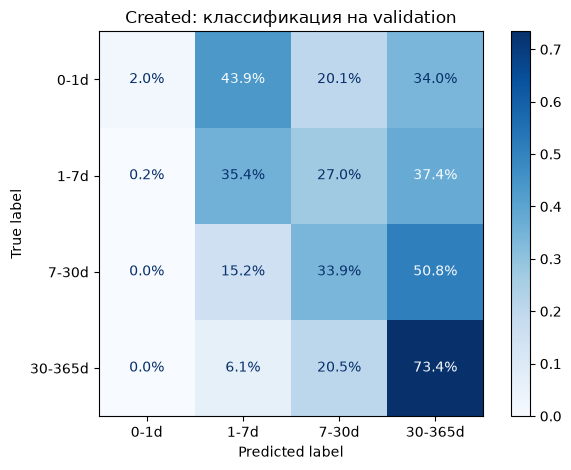

In [49]:
ConfusionMatrixDisplay.from_predictions( # the correct answers are on the diagonal
    y_valid,
    y_valid_pred,
    labels=CLASS_LABELS,
    normalize="true",
    values_format=".1%",
    cmap="Blues",
)

plt.title("Created: классификация на validation") 
plt.tight_layout()
plt.show()

In [50]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)


majority_class = y_train.mode().iloc[0]
rows = []

for split, X, y in (
    ("train", X_train, y_train),
    ("validation", X_valid, y_valid),
    ("test", X_test, y_test),
):
    predictions = classifier_72h.predict(X).ravel()
    baseline_predictions = [majority_class] * len(y)

    for model_name, pred in (
        ("CatBoost", predictions),
        ("Majority baseline", baseline_predictions),
    ):
        rows.append({
            "Split": split,
            "Model": model_name,
            "Accuracy": accuracy_score(y, pred),
            "Balanced accuracy": balanced_accuracy_score(y, pred),
            "Macro F1": f1_score(
                y, pred, average="macro", zero_division=0
            ),
        })

metrics_72h_df = pd.DataFrame(rows).set_index(["Split", "Model"])
metrics_72h_df.round(3)

Accuracy  Balanced accuracy  Macro F1
Split      Model                                                   
train      CatBoost              0.525              0.332     0.314
           Majority baseline     0.471              0.250     0.160
validation CatBoost              0.490              0.362     0.356
           Majority baseline     0.415              0.250     0.147
test       CatBoost              0.462              0.349     0.343
           Majority baseline     0.458              0.250     0.157

In [51]:
pd.concat(
    [metrics_created_df, metrics_24h_df, metrics_72h_df],
    keys=["created", "24h", "72h"],
    names=["Snapshot"]
).round(3)

Accuracy  Balanced accuracy  Macro F1
Snapshot Split      Model                                                   
created  train      CatBoost              0.372              0.288     0.225
                    Majority baseline     0.348              0.250     0.129
         validation CatBoost              0.314              0.289     0.275
                    Majority baseline     0.313              0.250     0.119
         test       CatBoost              0.351              0.300     0.294
                    Majority baseline     0.375              0.250     0.136
24h      train      CatBoost              0.483              0.327     0.301
                    Majority baseline     0.425              0.250     0.149
         validation CatBoost              0.444              0.344     0.334
                    Majority baseline     0.381              0.250     0.138
         test       CatBoost              0.440              0.345     0.333
                    Majority baseline     0.428              0.250     0.150
72h      train      CatBoost              0.525              0.332     0.314
                    Majority baseline     0.471              0.250     0.160
         validation CatBoost              0.490              0.362     0.356
                    Majority baseline     0.415              0.250     0.147
         test       CatBoost              0.462              0.349     0.343
                    Majority baseline     0.458              0.250     0.157